# FDTD From Scratch: A 1-D Cavity and a 2-D Waveguide

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jman4162/RF-and-Antenna-Tutorials/blob/main/FDTD_From_Scratch_Cavity_and_Waveguide_Tutorial.ipynb)

This notebook implements the finite-difference time-domain (FDTD) method of Yee (1966) in two settings and checks every computed resonance against both the exact discrete dispersion relation of the scheme and the analytic solution of Maxwell's equations. The problems come from a Virginia Tech ECE 5106 course project (spring 2016); the original MATLAB code is in [electromagnetics-work-samples](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/fdtd-waveguide).

Topics:

- The Yee grid: staggered E and H fields and leapfrog time stepping
- The Courant stability limit, and what happens when you exceed it
- Numerical dispersion, and why FDTD resonances sit slightly below the analytic ones
- Extracting resonant frequencies from a time series with a windowed FFT
- Compact 2-D FDTD: computing a waveguide's full dispersion curve $\omega(\beta)$ from a cross-section-only grid

## Units and conventions

Everything uses normalized units with $c = \varepsilon = \mu = 1$, so lengths and times share one unit and frequencies are in cycles per unit time. Real fields are stepped in time. In the 2-D waveguide section the fields carry an $e^{+i\beta z}$ dependence along the guide, so they are complex amplitudes that still evolve in real time.

## Part 1: a 1-D PEC cavity

With $E_x(z,t)$ and $H_y(z,t)$, Maxwell's curl equations reduce to

$$\frac{\partial E_x}{\partial t} = -\frac{\partial H_y}{\partial z}, \qquad \frac{\partial H_y}{\partial t} = -\frac{\partial E_x}{\partial z} .$$

The Yee scheme stores $E_x$ at nodes $z_k = k\Delta z$ and $H_y$ at the half nodes $z_{k+1/2}$, and updates them half a time step apart:

$$H_y^{n+1/2}(k+\tfrac12) = H_y^{n-1/2}(k+\tfrac12) - S\,[E_x^n(k+1) - E_x^n(k)],$$
$$E_x^{n+1}(k) = E_x^{n}(k) - S\,[H_y^{n+1/2}(k+\tfrac12) - H_y^{n+1/2}(k-\tfrac12)],$$

with Courant number $S = c\,\Delta t/\Delta z$. Perfect electric conductor (PEC) walls at $z = 0$ and $z = L$ hold $E_x = 0$.

**Exact answers to compare against.** The cavity modes are $E_x \propto \sin(m\pi z/L)$ with $f_m = m c/(2L)$. The discrete scheme instead obeys the numerical dispersion relation $\sin(\omega\Delta t/2)/(c\Delta t) = \sin(k\Delta z/2)/\Delta z$, so the frequencies the simulation should produce are

$$f_m^{\mathrm{FDTD}} = \frac{1}{\pi\Delta t}\arcsin\!\left[S\sin\!\left(\frac{m\pi\Delta z}{2L}\right)\right] .$$

The scheme is stable for $S \le 1$; at $S = 1$ (the "magic time step") the discrete and analytic frequencies coincide in 1-D.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

In [2]:
def fdtd_1d(N=30, L=30.0, S=0.5, steps=2**15, init="random", mode=5, probe=7, seed=1):
    """1-D Yee FDTD in a PEC cavity. Returns the E-field time series at `probe`, max|E| per step, and dt."""
    dz = L / N
    dt = S * dz
    z = np.arange(N + 1) * dz                    # E nodes, including both walls
    if init == "random":
        E = np.random.default_rng(seed).standard_normal(N + 1)
    else:
        E = np.sin(mode * np.pi * z / L)         # an exact cavity mode, zero on both walls
    E[0] = E[-1] = 0.0
    H = np.zeros(N)                              # H at the half nodes
    trace, emax = np.empty(steps), np.empty(steps)
    with np.errstate(over="ignore", invalid="ignore"):
        for n in range(steps):
            H -= S * (E[1:] - E[:-1])
            E[1:-1] -= S * (H[1:] - H[:-1])      # walls stay at zero
            trace[n] = E[probe]
            emax[n] = np.abs(E).max()
    return trace, emax, dt


def blackman_harris(n):
    """4-term Blackman-Harris window: sidelobes near -92 dB, so weak modes are not confused with leakage."""
    x = 2 * np.pi * np.arange(n) / (n - 1)
    return 0.35875 - 0.48829 * np.cos(x) + 0.14128 * np.cos(2 * x) - 0.01168 * np.cos(3 * x)


def peak_frequencies(signal, dt, fmin, fmax, max_peaks=8, floor=1e-3, pad=8):
    """Frequencies of spectral peaks, from a windowed, zero-padded FFT with quadratic interpolation."""
    n = len(signal)
    spectrum = np.abs(np.fft.fft(signal * blackman_harris(n), pad * n))
    f = np.fft.fftfreq(pad * n, dt)
    band = np.where((f > fmin) & (f < fmax))[0]
    s = spectrum[band]
    peaks = [i for i in range(1, len(s) - 1) if s[i] > s[i - 1] and s[i] >= s[i + 1] and s[i] > floor * s.max()]
    peaks = sorted(sorted(peaks, key=lambda i: -s[i])[:max_peaks])
    out = []
    for i in peaks:
        a, b, c = np.log(s[i - 1 : i + 2])
        out.append(f[band[i]] + 0.5 * (a - c) / (a - 2 * b + c) * (f[1] - f[0]))
    return np.array(out), f[band], s

### Resonances from a random initial field

Following the course project, the cavity has $L = 30$, $N = 30$ cells and $S = 0.5$. A random initial field contains every mode, so the spectrum of $E_x$ at one point shows all the resonances at once.

 m   FDTD        discrete    analytic    error vs analytic
 1   0.016661    0.016661    0.016667    0.03%
 2   0.033288    0.033288    0.033333    0.14%
 3   0.049846    0.049846    0.050000    0.31%
 4   0.066300    0.066300    0.066667    0.55%
 5   0.082616    0.082616    0.083333    0.86%
 6   0.098759    0.098759    0.100000    1.24%


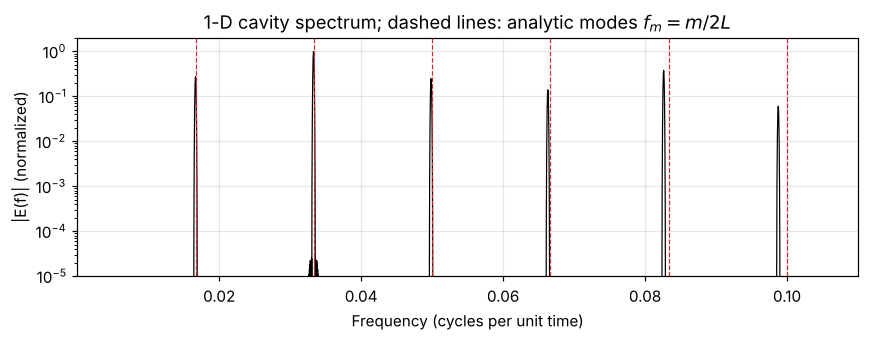

In [3]:
L, N, S = 30.0, 30, 0.5
trace, _, dt = fdtd_1d(N=N, L=L, S=S)
f_meas, f_axis, spec = peak_frequencies(trace, dt, 0.005, 0.105, max_peaks=6)

m = np.arange(1, 7)
dz = L / N
f_analytic = m / (2 * L)
f_discrete = np.arcsin(S * np.sin(m * np.pi * dz / (2 * L))) / (np.pi * dt)

err_discrete = np.abs(f_meas / f_discrete - 1)
err_analytic = np.abs(f_meas / f_analytic - 1)
assert len(f_meas) == 6 and err_discrete.max() < 1e-6

print(" m   FDTD        discrete    analytic    error vs analytic")
for row in zip(m, f_meas, f_discrete, f_analytic, err_analytic):
    print(f"{row[0]:2d}   {row[1]:.6f}    {row[2]:.6f}    {row[3]:.6f}    {100 * row[4]:.2f}%")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.semilogy(f_axis, spec / spec.max(), "k", lw=0.8)
for fa in f_analytic:
    ax.axvline(fa, color="C3", ls="--", lw=0.8)
ax.set(xlabel="Frequency (cycles per unit time)", ylabel="|E(f)| (normalized)",
       title="1-D cavity spectrum; dashed lines: analytic modes $f_m = m/2L$", ylim=(1e-5, 2))
plt.tight_layout()
plt.show()

The FDTD peaks match the discrete dispersion relation to better than one part in $10^6$. The gap to the analytic frequencies (up to 1.2% for $m = 6$) is numerical dispersion, and it shrinks as $(\Delta z)^2$. The next cell confirms the second-order convergence by refining the grid.

In [4]:
Ns = np.array([15, 30, 60, 120])
err_f1 = []
for n_cells in Ns:
    tr, _, dt_n = fdtd_1d(N=n_cells, L=L, S=S, steps=2**15, probe=max(1, n_cells // 4))
    f1 = peak_frequencies(tr, dt_n, 0.01, 0.025, max_peaks=1)[0][0]
    err_f1.append(abs(f1 * 2 * L - 1))
order = -np.polyfit(np.log(Ns), np.log(err_f1), 1)[0]
assert abs(order - 2) < 0.05
for n_cells, e in zip(Ns, err_f1):
    print(f"N = {n_cells:4d}: relative error of f_1 = {e:.2e}")
print(f"Observed convergence order: {order:.3f}")

N =   15: relative error of f_1 = 1.37e-03
N =   30: relative error of f_1 = 3.43e-04
N =   60: relative error of f_1 = 8.56e-05
N =  120: relative error of f_1 = 2.13e-05
Observed convergence order: 2.002


### A single mode, and the Courant limit

Starting from the exact $m = 5$ mode should excite only $m = 5$. This needs the initial field sampled at $z_k = k\Delta z$ for $k = 0, \dots, N$, so that it is zero on both walls. The original 2016 script sampled at $k = 1, \dots, N+1$, which left $E_x = \pm 0.5$ on the walls; zeroing the walls then created jumps that excited other modes ([original code](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/fdtd-waveguide)).

The second plot shows stability: at $S = 1$ the field stays bounded indefinitely, and at $S = 1.02$ the highest-frequency grid mode grows exponentially.

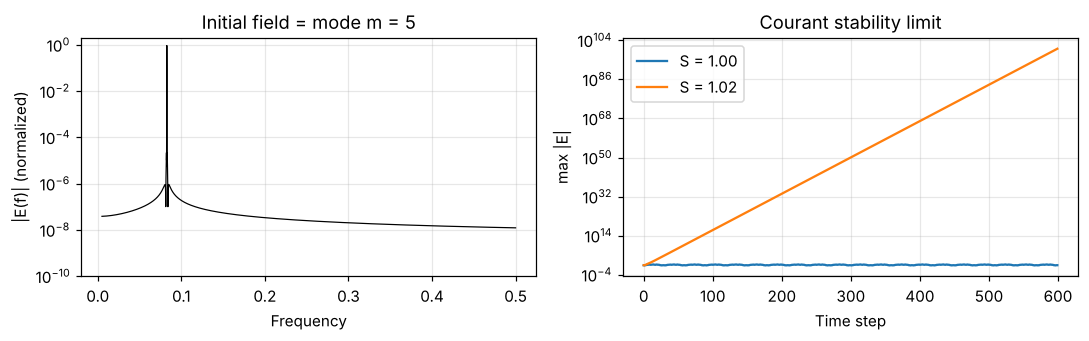

Peak at f = 0.082616 (discrete m = 5: 0.082616); largest amplitude at any other mode: 2.0e-07 of the peak


In [5]:
trace5, _, dt5 = fdtd_1d(init="mode", mode=5)
f5, f_axis5, spec5 = peak_frequencies(trace5, dt5, 0.005, 0.5, max_peaks=1)
assert abs(f5[0] / f_discrete[4] - 1) < 1e-6
# Spectral amplitude at the other cavity modes, relative to the m = 5 peak
others = [np.interp(f, f_axis5, spec5) for i, f in enumerate(f_discrete) if i != 4]
leak = max(others) / np.interp(f_discrete[4], f_axis5, spec5)
assert leak < 1e-5

steps = 600
_, emax_stable, _ = fdtd_1d(S=1.0, steps=steps)
_, emax_unstable, _ = fdtd_1d(S=1.02, steps=steps)
assert emax_stable.max() < 10 and emax_unstable[steps // 2] > 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
ax1.semilogy(f_axis5[::8], spec5[::8] / spec5.max(), "k", lw=0.8)   # every 8th point = the un-padded FFT bins
ax1.set(xlabel="Frequency", ylabel="|E(f)| (normalized)", title="Initial field = mode m = 5", ylim=(1e-10, 2))
ax2.semilogy(emax_stable, label="S = 1.00")
ax2.semilogy(emax_unstable, label="S = 1.02")
ax2.set(xlabel="Time step", ylabel="max |E|", title="Courant stability limit")
ax2.legend()
plt.tight_layout()
plt.show()
print(f"Peak at f = {f5[0]:.6f} (discrete m = 5: {f_discrete[4]:.6f}); "
      f"largest amplitude at any other mode: {leak:.1e} of the peak")

## Part 2: waveguide dispersion with compact 2-D FDTD

A uniform waveguide along $z$ supports fields of the form $\mathbf{F}(x,y,t)\,e^{+i\beta z}$. Substituting $\partial/\partial z \to i\beta$ into Maxwell's equations leaves a 2-D problem on the cross-section with all six field components:

$$\partial_t H_x = -(\partial_y E_z - i\beta E_y), \quad \partial_t H_y = -(i\beta E_x - \partial_x E_z), \quad \partial_t H_z = -(\partial_x E_y - \partial_y E_x),$$
$$\partial_t E_x = \partial_y H_z - i\beta H_y, \quad \partial_t E_y = i\beta H_x - \partial_x H_z, \quad \partial_t E_z = \partial_x H_y - \partial_y H_x .$$

This is the compact 2-D FDTD method (Xiao, Vahldieck and Jin, 1992). Placing the components on the cross-section's Yee cell as below puts each $i\beta$ term at the same location as the field it updates, so no interpolation is needed:

| Component | $E_x$ | $E_y$ | $E_z$ | $H_x$ | $H_y$ | $H_z$ |
|---|---|---|---|---|---|---|
| Position $(i, j)$ | $(i+\frac12, j)$ | $(i, j+\frac12)$ | $(i, j)$ | $(i, j+\frac12)$ | $(i+\frac12, j)$ | $(i+\frac12, j+\frac12)$ |

PEC walls at $x = 0, a$ and $y = 0, b$ hold the tangential electric field at zero. One run at fixed $\beta$ gives every mode frequency $\omega(\beta)$; sweeping $\beta$ traces the dispersion diagram. The time step must satisfy $c\,\Delta t \le \left[\Delta x^{-2} + \Delta y^{-2} + (\beta/2)^2\right]^{-1/2}$.

**Exact answers to compare against.** For a rectangular PEC guide the $\mathrm{TE}_{mn}$ and $\mathrm{TM}_{mn}$ modes satisfy $\omega^2 = (m\pi/a)^2 + (n\pi/b)^2 + \beta^2$. Because $\beta$ enters exactly, the scheme's discrete dispersion relation is

$$\left(\frac{2}{\Delta t}\right)^2 \sin^2\frac{\omega\Delta t}{2} = \left(\frac{2}{\Delta x}\right)^2 \sin^2\frac{m\pi\Delta x}{2a} + \left(\frac{2}{\Delta y}\right)^2 \sin^2\frac{n\pi\Delta y}{2b} + \beta^2 .$$

In [6]:
def fdtd_2d(beta, a=2.0, b=1.0, Nx=40, Ny=20, steps=2**14, safety=0.9,
            source=(7, 6), probe=(29, 13), dft_omega=None):
    """Compact 2-D FDTD for a rectangular PEC waveguide with fields ~ exp(+i beta z).

    Returns the Hz time series at `probe`, dt, the grid spacings, and (optionally) a running DFT of Hz.
    """
    dx, dy = a / Nx, b / Ny
    dt = safety / np.sqrt(1 / dx**2 + 1 / dy**2 + (beta / 2) ** 2)
    Ex = np.zeros((Nx, Ny + 1), complex)
    Ey = np.zeros((Nx + 1, Ny), complex)
    Ez = np.zeros((Nx + 1, Ny + 1), complex)
    Hx = np.zeros((Nx + 1, Ny), complex)
    Hy = np.zeros((Nx, Ny + 1), complex)
    Hz = np.zeros((Nx, Ny), complex)
    # Impulse excitation away from every symmetry line, so no low-order mode has a node there
    Hz[source] = 1.0
    Ez[source[0] + 3, source[1] + 2] = 1.0
    ib = 1j * beta
    trace = np.empty(steps, complex)
    dft = np.zeros((Nx, Ny), complex) if dft_omega is not None else None
    for n in range(steps):
        Hx -= dt * ((Ez[:, 1:] - Ez[:, :-1]) / dy - ib * Ey)
        Hy -= dt * (ib * Ex - (Ez[1:, :] - Ez[:-1, :]) / dx)
        Hz -= dt * ((Ey[1:, :] - Ey[:-1, :]) / dx - (Ex[:, 1:] - Ex[:, :-1]) / dy)
        Ex[:, 1:-1] += dt * ((Hz[:, 1:] - Hz[:, :-1]) / dy - ib * Hy[:, 1:-1])
        Ey[1:-1, :] += dt * (ib * Hx[1:-1, :] - (Hz[1:, :] - Hz[:-1, :]) / dx)
        Ez[1:-1, 1:-1] += dt * ((Hy[1:, 1:-1] - Hy[:-1, 1:-1]) / dx - (Hx[1:-1, 1:] - Hx[1:-1, :-1]) / dy)
        trace[n] = Hz[probe]
        if dft is not None:
            dft += Hz * np.exp(1j * dft_omega * n * dt) * dt
    return trace, dt, (dx, dy), dft


def omega_analytic(m, n, beta, a=2.0, b=1.0):
    return np.sqrt((m * np.pi / a) ** 2 + (n * np.pi / b) ** 2 + beta**2)


def omega_discrete(m, n, beta, dt, dx, dy, a=2.0, b=1.0):
    rhs = (2 / dx * np.sin(m * np.pi * dx / (2 * a))) ** 2 + (2 / dy * np.sin(n * np.pi * dy / (2 * b))) ** 2 + beta**2
    return 2 / dt * np.arcsin(dt / 2 * np.sqrt(rhs))

### Mode spectrum at cutoff ($\beta = 0$)

The guide is $a \times b = 2 \times 1$ on a $40 \times 20$ grid, the same 2:1 aspect ratio as the project's 10 cm × 5 cm guide. The source and probe sit away from the symmetry lines. (In the original project the probe was at the guide's center, which is a node of $H_z$ for the $\mathrm{TE}_{10}$ mode, so the dominant mode barely appeared in the spectrum.)

mode           FDTD      discrete   analytic
TE10          1.57056   1.57056    1.57080
TE20 / TE01   3.13967   3.13967    3.14159
TE11 / TM11   3.51116   3.51116    3.51241
TE21 / TM21   4.44201   4.44201    4.44288
TE30          4.70589   4.70589    4.71239


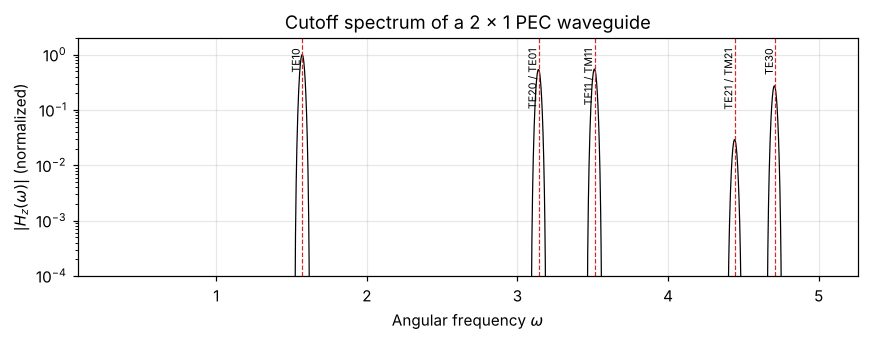

In [7]:
a, b = 2.0, 1.0
trace0, dt0, (dx, dy), _ = fdtd_2d(0.0)
w_peaks0, f_axis0, spec0 = peak_frequencies(trace0, dt0, 0.05, 0.8, max_peaks=6)
w_peaks0 = 2 * np.pi * w_peaks0

labels = {"TE10": (1, 0), "TE20 / TE01": (2, 0), "TE11 / TM11": (1, 1), "TE21 / TM21": (2, 1), "TE30": (3, 0)}
print("mode           FDTD      discrete   analytic")
for name, (mm, nn) in labels.items():
    w_d, w_a = omega_discrete(mm, nn, 0.0, dt0, dx, dy), omega_analytic(mm, nn, 0.0)
    w_f = w_peaks0[np.argmin(np.abs(w_peaks0 - w_d))]
    assert abs(w_f / w_d - 1) < 1e-4
    print(f"{name:13s} {w_f:.5f}   {w_d:.5f}    {w_a:.5f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.semilogy(2 * np.pi * f_axis0, spec0 / spec0.max(), "k", lw=0.8)
for name, (mm, nn) in labels.items():
    ax.axvline(omega_analytic(mm, nn, 0.0), color="C3", ls="--", lw=0.8)
    ax.text(omega_analytic(mm, nn, 0.0), 1.3, name, rotation=90, fontsize=7, ha="right", va="top")
ax.set(xlabel="Angular frequency $\\omega$", ylabel="$|H_z(\\omega)|$ (normalized)",
       title="Cutoff spectrum of a 2 × 1 PEC waveguide", ylim=(1e-4, 2))
plt.tight_layout()
plt.show()

### The dispersion diagram

Sweeping $\beta$ and collecting the spectral peaks traces the hyperbolas $\omega = \sqrt{\omega_c^2 + \beta^2}$. The check below compares the lowest peak at each $\beta$ with the $\mathrm{TE}_{10}$ prediction.

 beta    FDTD TE10   discrete   analytic   error vs analytic
 0.00   1.57056    1.57056    1.57080    0.015%
 0.50   1.64826    1.64826    1.64845    0.012%
 1.00   1.86203    1.86203    1.86210    0.004%
 1.50   2.17210    2.17210    2.17196    0.006%
 2.00   2.54355    2.54355    2.54311    0.017%
 2.50   2.95339    2.95339    2.95252    0.029%
 3.00   3.38780    3.38780    3.38636    0.043%


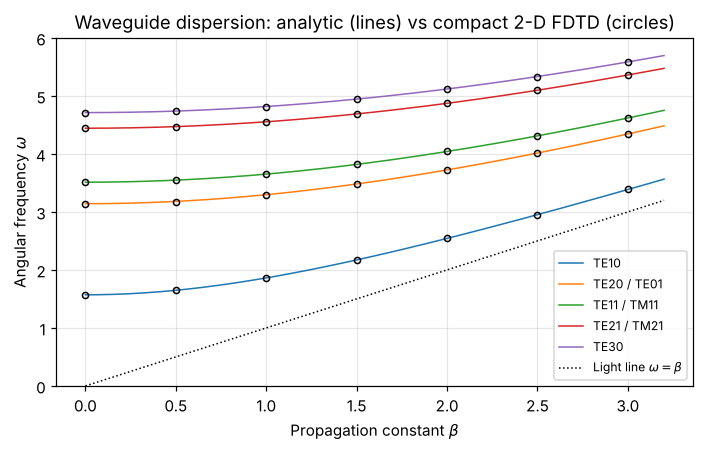

In [8]:
betas = np.linspace(0, 3, 7)
lowest, all_peaks = [], []
for beta in betas:
    tr, dt_b, (dx, dy), _ = fdtd_2d(beta)
    w = 2 * np.pi * peak_frequencies(tr, dt_b, 0.05, 0.9, max_peaks=6)[0]
    all_peaks.append(w)
    w_d, w_a = omega_discrete(1, 0, beta, dt_b, dx, dy), omega_analytic(1, 0, beta)
    assert abs(w.min() / w_d - 1) < 1e-4 and abs(w.min() / w_a - 1) < 5e-3
    lowest.append((beta, w.min(), w_d, w_a))

print(" beta    FDTD TE10   discrete   analytic   error vs analytic")
for beta, w_f, w_d, w_a in lowest:
    print(f"{beta:5.2f}   {w_f:.5f}    {w_d:.5f}    {w_a:.5f}    {100 * abs(w_f / w_a - 1):.3f}%")

bb = np.linspace(0, 3.2, 200)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name, (mm, nn) in labels.items():
    ax.plot(bb, omega_analytic(mm, nn, bb), lw=1, label=name)
ax.plot(bb, bb, "k:", lw=1, label="Light line $\\omega = \\beta$")
for beta, w in zip(betas, all_peaks):
    ax.plot(np.full(len(w), beta), w, "ko", ms=4, mfc="none")
ax.set(xlabel="Propagation constant $\\beta$", ylabel="Angular frequency $\\omega$",
       title="Waveguide dispersion: analytic (lines) vs compact 2-D FDTD (circles)", ylim=(0, 6))
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### The TE$_{10}$ field pattern

A running discrete Fourier transform of $H_z$ at the $\mathrm{TE}_{10}$ frequency extracts that mode's field pattern from the same broadband simulation. It should vary as $\cos(\pi x/a)$ across the width and be uniform in $y$.

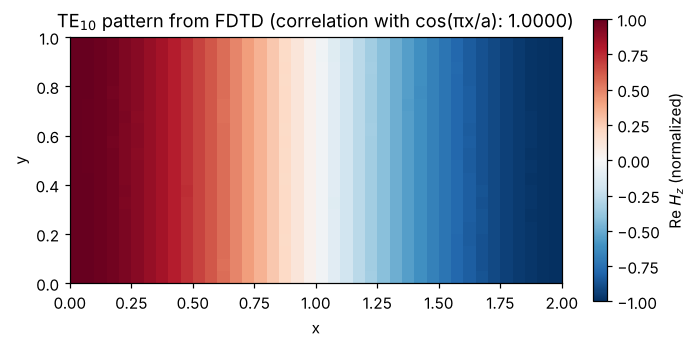

In [9]:
w10 = omega_discrete(1, 0, 0.0, dt0, dx, dy)
_, _, _, dft = fdtd_2d(0.0, steps=2**14, dft_omega=w10)
pattern = dft * np.conj(dft.flat[np.abs(dft).argmax()])     # remove the arbitrary global phase
pattern = pattern.real / np.abs(pattern.real).max()

x_h = (np.arange(40) + 0.5) * dx
expected = np.cos(np.pi * x_h / a)[:, None] * np.ones((1, 20))
corr = abs(np.sum(pattern * expected)) / np.sqrt(np.sum(pattern**2) * np.sum(expected**2))
assert corr > 0.99

fig, ax = plt.subplots(figsize=(6.5, 3.2))
im = ax.imshow(pattern.T, origin="lower", extent=[0, a, 0, b], cmap="RdBu_r", vmin=-1, vmax=1, aspect="equal")
fig.colorbar(im, ax=ax, label="Re $H_z$ (normalized)")
ax.set(xlabel="x", ylabel="y", title=f"TE$_{{10}}$ pattern from FDTD (correlation with cos(πx/a): {corr:.4f})")
ax.grid(False)
plt.tight_layout()
plt.show()

## Notes on the original coursework

The 2016 MATLAB scripts ([source](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/fdtd-waveguide)) were reviewed while preparing this notebook. The issues, and how this version handles them:

- **1-D initial field off by one node.** The "single mode" start was sampled at $k = 1, \dots, N+1$ instead of $k = 0, \dots, N$, so it was not a cavity mode. Fixed above, and checked by the single-peak spectrum.
- **2-D probe on a field node.** The probe sat at the guide's center, where $H_z$ of the $\mathrm{TE}_{10}$ mode is zero. The source and probe here sit off every symmetry line.
- **2-D excitation and $\beta$ sweep.** The script computed a Gaussian pulse but started from a fixed $\mathrm{TE}_{10}$ field at $\beta = 0$; the report's dispersion study was done by editing parameters by hand. Here an impulse excites every mode, and the dispersion diagram comes from a loop over $\beta$.
- **Memory.** The original stored every time step of all six components (about 1.25 GB). This version keeps only the current fields plus a probe trace.

## References

- K. S. Yee, "Numerical solution of initial boundary value problems involving Maxwell's equations in isotropic media," *IEEE Trans. Antennas Propag.*, vol. 14, no. 3, pp. 302–307, 1966.
- A. Taflove and S. C. Hagness, *Computational Electrodynamics: The Finite-Difference Time-Domain Method*, 3rd ed., Artech House, 2005.
- S. Xiao, R. Vahldieck, and H. Jin, "Full-wave analysis of guided wave structures using a novel 2-D FDTD," *IEEE Microw. Guided Wave Lett.*, vol. 2, no. 5, pp. 165–167, 1992.
- D. M. Pozar, *Microwave Engineering*, 4th ed., Wiley, 2012, ch. 3.